In [7]:
import os
import sys

# Move up one directory from 'notebooks' to 'root_dir' and add it to python path
root_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
if root_dir not in sys.path:
    sys.path.append(root_dir)

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm

from src.mpc_l import PCLayer
from src.mpc_trainer import PCTrainer, PCTrainingArguments

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "mps")
print(f'using {device}')

using mps


In [2]:
# data parameters
mean = 1.               
variance = 5.              
batch_size = 256    
nm_batches = 150        

# generate data
data = [mean + np.sqrt(variance)*torch.randn(batch_size, 1) for i in range(nm_batches)]

In [3]:
class BiasLayer(nn.Module):
    def __init__(self, out_features):
        super(BiasLayer, self).__init__()
        self.bias = nn.Parameter(torch.Tensor(1,out_features), requires_grad=True)
        nn.init.constant_(self.bias, 0.0)

    def forward(self, x):
        return torch.zeros_like(x) + self.bias  # return the prior mean \mu with the same shape as the input x to make sure the batch size is the same

In [4]:
latent_size = 1     # number of latent states in latent layer
output_size = 1     # number of dimensions in data 
loss_fn = lambda output, _target: 0.5*(output - _target).pow(2).sum()  # loss function is mean squared error

mcpc_model = nn.Sequential(
    BiasLayer(latent_size),
    PCLayer(),
    nn.Linear(latent_size, output_size, bias=False),
)
mcpc_model.train();

In [5]:
class SGDLD(optim.SGD):
    def __init__(self, params, lr=0.01, weight_decay=0, noise_var=1.):
        super(SGDLD, self).__init__(params, lr, weight_decay)
        self.noise_var = noise_var

    def step(self, closure=None):
        super(SGDLD, self).step(closure)

        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None:
                    continue
                p.data.add_(np.sqrt(2*self.noise_var*group['lr'])*torch.randn_like(p))

In [10]:
T_mixing = 250                      # number of inference iterations without parameter gradient accumulation
T_sampling = 1                      # number of inference iterations without parameter gradient accumulation
update_x_at = 'all'                 # update latent state x at every iteration
optimizer_x_fn = SGDLD              # noisy optimizer for latent state x
optimizer_x_kwargs = {'lr': 0.01}   # optimizer parameters for latent state x
update_p_at = 'last'                # update parameters p at the last iteration
optimizer_p_fn = optim.Adam         # optimizer for parameters p
optimizer_p_kwargs = {'lr': 0.1}    # optimizer parameters for p
plot_progress_at = []               # plot progress every inference iterations

n_epochs = 5

args = PCTrainingArguments(
    T=T_mixing+T_sampling,
    num_train_epochs=n_epochs,
    optimizer_x_cls = optimizer_x_fn,
    optimizer_x_kwargs = optimizer_x_kwargs,
    optimizer_p_cls = optimizer_p_fn,
    optimizer_p_kwargs = optimizer_p_kwargs,
    update_p_at = update_p_at,
    device=device,
    eval_strategy="no",
)

trainer = PCTrainer(
    mcpc_model, 
	args=args,
	loss_fn=loss_fn
)

In [11]:
mcpc_model.train()
for layer in trainer.pc_layers():
    layer.train()

for idx_epoch in range(n_epochs):
    pbar = tqdm(data, desc=f"Epoch: {idx_epoch+1}")
    for y in pbar:
        y = y.to(device)
        pseudo_input = torch.zeros(y.size(0), 1, device=device)
        logs = trainer.training_step(pseudo_input, y)
        pbar.set_postfix(
            loss=f"{logs['loss']:.3f}",
            energy=f"{logs['energy']:.3f}",
            sup=f"{logs['supervised']:.3f}",
        )

Epoch: 5: 100%|██████████| 150/150 [02:18<00:00,  1.08it/s, energy=130.383, loss=251.570, sup=121.187]


sample: 100%|██████████| 2000/2000 [00:00<00:00, 4685.16it/s]


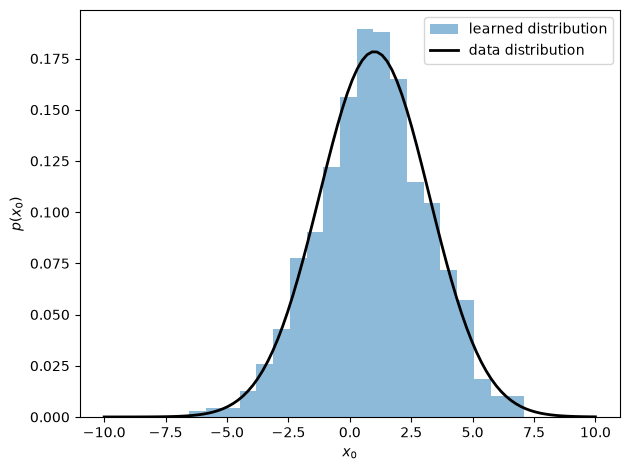

In [12]:
model_generation = nn.Sequential(
    *list(mcpc_model.children()),
    PCLayer(),
).to(device)
model_generation.train()
for m in model_generation.modules():
    if isinstance(m, PCLayer):
        m.train()

nm_samples = 1024
T_gen = 2000
step_x = 0.01
noise_var = 1.0

pseudo_input = torch.zeros(nm_samples, 1, device=device)

# allocate x
for m in model_generation.modules():
    if isinstance(m, PCLayer):
        m.set_sample_x(True)
_ = model_generation(pseudo_input)

xs = [m.x for m in model_generation.modules() if isinstance(m, PCLayer) and m.x is not None]
opt_x = SGDLD(xs, lr=step_x, noise_var=noise_var)

for t in tqdm(range(T_gen), desc="sample"):
    out = model_generation(pseudo_input)
    energy = sum(
        m.energy for m in model_generation.modules()
        if isinstance(m, PCLayer) and m.energy is not None
    )
    opt_x.zero_grad()
    energy.backward()
    opt_x.step()

last_pc = [m for m in model_generation.modules() if isinstance(m, PCLayer)][-1]
samples = last_pc.x.detach().cpu().numpy()

plt.hist(samples.reshape(-1), bins=20, alpha=0.5, density=True, label="learned distribution")
x = np.linspace(-10, 10, 100)
plt.plot(
    x,
    1 / np.sqrt(2 * np.pi * variance) * np.exp(-0.5 * (x - mean) ** 2 / variance),
    "k",
    linewidth=2,
    label="data distribution",
)
plt.xlabel(r"$x_0$")
plt.ylabel(r"$p(x_0)$")
plt.legend()
plt.tight_layout()
plt.show()